In [1]:
import cv2 

# Vista previa de una cara de ejemplo del dataset
img = cv2.imread('haarcascade_dataset/imgs_axel/cara1.jpg')
print("Dimensiones de la imagen:", img.shape[0], "alto,", img.shape[1], "ancho,", img.shape[2], "canales.")


Dimensiones de la imagen: 116 alto, 116 ancho, 3 canales.


# Convolutional Neural Networks

# Importar Librerías

In [2]:
import numpy as np
import os
import re
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [3]:
import keras
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from keras.models import Sequential,Model
from tensorflow.keras.layers import Input
from keras.layers import Dense, Dropout, Flatten
#from keras.layers import Conv2D, MaxPooling2D
#from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    BatchNormalization, SeparableConv2D, MaxPooling2D, Activation, Flatten, Dropout, Dense, Conv2D
)
from keras.layers import LeakyReLU

I0000 00:00:1795532079.305293   12206 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795532084.873929   12206 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Cargar set de Imágenes

In [4]:
# Cargar set de Imágenes de rostros
dirname = 'haarcascade_dataset'
imgpath = dirname + os.sep 

images = []
directories = []
dircount = []
prevRoot = ''
cant = 0

print("Leyendo imágenes de ", imgpath)

for root, dirnames, filenames in sorted(os.walk(imgpath)):
    if '.git' in root or root == imgpath or root == imgpath.rstrip(os.sep):
        continue
    for filename in sorted(filenames):
        if re.search(r'\.(jpg|jpeg|png|bmp|tiff)$', filename, re.IGNORECASE):
            cant += 1
            filepath = os.path.join(root, filename)
            image = plt.imread(filepath)
            if len(image.shape) == 3:
                if image.shape[2] == 4:
                    image = image[:, :, :3]
                # Redimensionamos a 48x48 para capturar bien los rasgos faciales
                image_resized = cv2.resize(image, (48, 48))
                images.append(image_resized)
            if prevRoot != root:
                prevRoot = root
                directories.append(root)
                dircount.append(cant)
                cant = 0

dircount.append(cant)
dircount = dircount[1:]
dircount[0] = dircount[0] + 1

print('Directorios leídos:', len(directories))
print("Imágenes en cada directorio:", dircount)
print('Total de imágenes:', sum(dircount))


Leyendo imágenes de  haarcascade_dataset/
Directorios leídos: 5
Imágenes en cada directorio: [1345, 1152, 1134, 1326, 745]
Total de imágenes: 5702


# Creamos las etiquetas

In [5]:
labels=[]
indice=0
for cantidad in dircount:
    for i in range(cantidad):
        labels.append(indice)
    indice=indice+1
print("Cantidad etiquetas creadas: ",len(labels))


Cantidad etiquetas creadas:  5702


In [6]:
# Guardamos los nombres de las personas (subcarpetas)
deportes = []
for indice, directorio in enumerate(directories):
    name = directorio.split(os.sep)
    clase = name[-1].replace('imgs_', '').capitalize()
    print(indice, clase)
    deportes.append(clase)


0 Axel
1 Checo
2 Hugo
3 Miguel
4 Nacho


In [7]:
y = np.array(labels)
X = np.array(images, dtype=np.uint8) #convierto de lista a numpy



# Find the unique numbers from the train labels
classes = np.unique(y)
nClasses = len(classes)
print('Total number of outputs : ', nClasses)
print('Output classes : ', classes)

Total number of outputs :  5
Output classes :  [0 1 2 3 4]


# Creamos Sets de Entrenamiento y Test

In [8]:
train_X,test_X,train_Y,test_Y = train_test_split(X,y,test_size=0.2)
print('Training data shape : ', train_X.shape, train_Y.shape)
print('Testing data shape : ', test_X.shape, test_Y.shape)

Training data shape :  (4561, 48, 48, 3) (4561,)
Testing data shape :  (1141, 48, 48, 3) (1141,)


Text(0.5, 1.0, 'Ground Truth : 0')

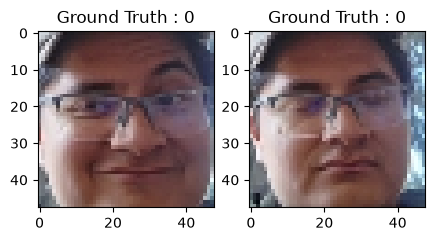

In [9]:
plt.figure(figsize=[5,5])

# Display the first image in training data
plt.subplot(121)
plt.imshow(train_X[0,:,:], cmap='gray')
plt.title("Ground Truth : {}".format(train_Y[0]))

# Display the first image in testing data
plt.subplot(122)
plt.imshow(test_X[0,:,:], cmap='gray')
plt.title("Ground Truth : {}".format(test_Y[0]))

# Preprocesamos las imagenes

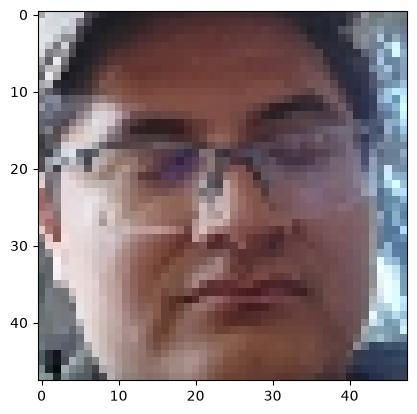

In [10]:
train_X = train_X.astype('float32')
test_X = test_X.astype('float32')
train_X = train_X/255.
test_X = test_X/255.
plt.imshow(test_X[0,:,:])

## Hacemos el One-hot Encoding para la red

In [11]:
# Change the labels from categorical to one-hot encoding
train_Y_one_hot = to_categorical(train_Y)
test_Y_one_hot = to_categorical(test_Y)

# Display the change for category label using one-hot encoding
print('Original label:', train_Y[0])
print('After conversion to one-hot:', train_Y_one_hot[0])

Original label: 0
After conversion to one-hot: [1. 0. 0. 0. 0.]


# Creamos el Set de Entrenamiento y Validación

In [12]:
#Mezclar todo y crear los grupos de entrenamiento y testing
train_X,valid_X,train_label,valid_label = train_test_split(train_X, train_Y_one_hot, test_size=0.2, random_state=13)

In [13]:
print(train_X.shape,valid_X.shape,train_label.shape,valid_label.shape)

(3648, 48, 48, 3) (913, 48, 48, 3) (3648, 5) (913, 5)


# Creamos el modelo de CNN

In [14]:
# Parámetros de entrenamiento
epochs = 10     # Con Adam, 10 épocas alcanzan >99% de precisión
batch_size = 64 # Imágenes por lote


In [15]:
# ==============================================================================
# DEFINICIÓN DE LA RED NEURONAL CONVOLUCIONAL (CNN) - EXPLICADO FOR DUMMIES
# ==============================================================================
sport_model = Sequential()

# Bloque 1: Detecta líneas y bordes básicos
sport_model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same', input_shape=(48, 48, 3)))
sport_model.add(MaxPooling2D((2, 2)))

# Bloque 2 (CAPA AGREGADA): Detecta rasgos faciales (ojos, nariz, boca)
sport_model.add(Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'))
sport_model.add(MaxPooling2D((2, 2)))
sport_model.add(Dropout(0.25))

# Clasificador final
sport_model.add(Flatten())
sport_model.add(Dense(128, activation='relu'))
sport_model.add(Dropout(0.5))
sport_model.add(Dense(nClasses, activation='softmax'))

sport_model.summary()


/home/hugo64/Documentos/escuela/IA/proyecto 2/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1795532091.137955   12206 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,813 (4.58 MB)

 Trainable params: 1,199,813 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
sport_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,813 (4.58 MB)

 Trainable params: 1,199,813 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
sport_model.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer='adam',
    metrics=['accuracy']
)


# Entrenamos el modelo: Aprende a clasificar imágenes

In [18]:
# este paso puede tomar varios minutos, dependiendo de tu ordenador, cpu y memoria ram libre
sport_train = sport_model.fit(train_X, train_label, batch_size=batch_size,epochs=epochs,verbose=1,validation_data=(valid_X, valid_label))

Epoch 1/10


W0000 00:00:1795532091.589866   12206 cpu_allocator_impl.cc:82] Allocation of 100859904 exceeds 10% of free system memory.


57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 134ms/step - accuracy: 0.7453 - loss: 0.7102 - val_accuracy: 0.9880 - val_loss: 0.0777
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.9849 - loss: 0.0817 - val_accuracy: 0.9956 - val_loss: 0.0369
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 124ms/step - accuracy: 0.9942 - loss: 0.0351 - val_accuracy: 0.9967 - val_loss: 0.0275
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - accuracy: 0.9953 - loss: 0.0295 - val_accuracy: 0.9967 - val_loss: 0.0295
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 131ms/step - accuracy: 0.9962 - loss: 0.0240 - val_accuracy: 0.9967 - val_loss: 0.0248
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 126ms/step - accuracy: 0.9964 - loss: 0.0189 - val_accuracy: 0.9967 - val_loss: 0.0257
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.9956 - loss: 0.0192 - val_accuracy: 0.9967 - val_loss: 0.0371
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.9984 - loss: 0.0158 - val_accuracy: 0.9967 - val_

In [19]:
# Guardamos el modelo entrenado
sport_model.save("modelo_caras.h5")
print("Modelo guardado exitosamente en modelo_caras.h5")


Modelo guardado exitosamente en modelo_caras.h5


# Evaluamos la red

In [20]:
test_eval = sport_model.evaluate(test_X, test_Y_one_hot, verbose=1)

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 1.0000 - loss: 0.0015


In [21]:
print('Test loss:', test_eval[0])
print('Test accuracy:', test_eval[1])

Test loss: 0.0014645349001511931
Test accuracy: 1.0


In [22]:
sport_train.history

{'accuracy': [0.7453399300575256,
  0.984923243522644,
  0.9942434430122375,
  0.9953399300575256,
  0.9961622953414917,
  0.9964364171028137,
  0.9956140518188477,
  0.9983552694320679,
  0.9980811476707458,
  0.9972587823867798],
 'loss': [0.7101749181747437,
  0.08169678598642349,
  0.03507029637694359,
  0.0295010507106781,
  0.024028494954109192,
  0.01887540891766548,
  0.01916806399822235,
  0.015798790380358696,
  0.015494310297071934,
  0.013347703963518143],
 'val_accuracy': [0.9879518151283264,
  0.9956188201904297,
  0.9967141151428223,
  0.9967141151428223,
  0.9967141151428223,
  0.9967141151428223,
  0.9967141151428223,
  0.9967141151428223,
  0.9967141151428223,
  0.9967141151428223],
 'val_loss': [0.07767859846353531,
  0.03691430389881134,
  0.027489377185702324,
  0.02949175052344799,
  0.024827945977449417,
  0.02566252276301384,
  0.03709270805120468,
  0.027274491265416145,
  0.03074399009346962,
  0.029231565073132515]}

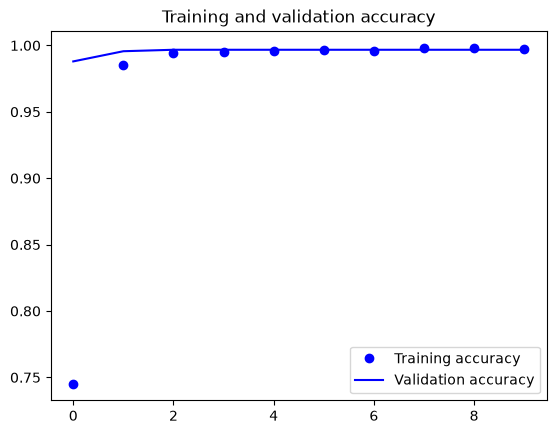

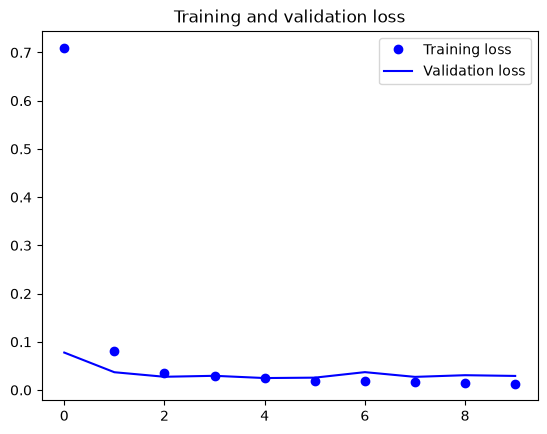

In [23]:
accuracy = sport_train.history['accuracy']
val_accuracy = sport_train.history['val_accuracy']
loss = sport_train.history['loss']
val_loss = sport_train.history['val_loss']
epochs = range(len(accuracy))
plt.plot(epochs, accuracy, 'bo', label='Training accuracy')
plt.plot(epochs, val_accuracy, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()
plt.plot(epochs, loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()
plt.show()

In [24]:
predicted_classes2 = sport_model.predict(test_X)

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


In [25]:
predicted_classes=[]
for predicted_sport in predicted_classes2:
    predicted_classes.append(predicted_sport.tolist().index(max(predicted_sport)))
predicted_classes=np.array(predicted_classes)

In [26]:
predicted_classes.shape, test_Y.shape

((1141,), (1141,))

# Aprendamos de los errores: Qué mejorar

Found 1141 correct labels


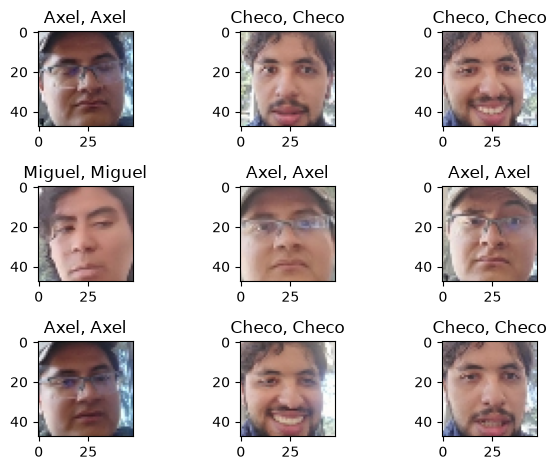

In [27]:
correct = np.where(predicted_classes == test_Y)[0]
print("Found %d correct labels" % len(correct))
for i, c in enumerate(correct[0:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(test_X[c])
    plt.title("{}, {}".format(deportes[predicted_classes[c]], deportes[test_Y[c]]))
plt.tight_layout()
plt.show()


In [28]:
incorrect = np.where(predicted_classes != test_Y)[0]
print("Found %d incorrect labels" % len(incorrect))
for i, inc in enumerate(incorrect[0:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(test_X[inc])
    plt.title("{}, {}".format(deportes[predicted_classes[inc]], deportes[test_Y[inc]]))
plt.tight_layout()
plt.show()


Found 0 incorrect labels


<Figure size 640x480 with 0 Axes>

In [29]:
target_names = [deportes[i] if i < len(deportes) else f"Class {i}" for i in range(nClasses)]
print(classification_report(test_Y, predicted_classes, target_names=target_names))


              precision    recall  f1-score   support

        Axel       1.00      1.00      1.00       246
       Checo       1.00      1.00      1.00       222
        Hugo       1.00      1.00      1.00       255
      Miguel       1.00      1.00      1.00       278
       Nacho       1.00      1.00      1.00       140

    accuracy                           1.00      1141
   macro avg       1.00      1.00      1.00      1141
weighted avg       1.00      1.00      1.00      1141



In [30]:
import cv2

# Cargamos el detector de caras y abrimos la cámara (0) o un video ('video.mp4')
rostro = cv2.CascadeClassifier('haarcascade_dataset/haarcascade_frontalface_alt.xml')
cap = cv2.VideoCapture(0)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Detectamos caras en escala de grises
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    caras = rostro.detectMultiScale(gray, 1.1, 3, minSize=(40, 40))

    for (x, y, w, h) in caras:
        # 1. Recortar cara, pasar a RGB, redimensionar a 48x48 y normalizar (0 a 1)
        cara = cv2.cvtColor(frame[y:y+h, x:x+w], cv2.COLOR_BGR2RGB)
        cara = cv2.resize(cara, (48, 48)) / 255.0

        # 2. Predecir a qué integrante pertenece
        probs = sport_model.predict(np.array([cara]), verbose=0)[0]
        nombre = deportes[np.argmax(probs)]
        texto = f"{nombre} ({np.max(probs)*100:.1f}%)"

        # 3. Dibujar recuadro y nombre en el fotograma
        cv2.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)
        cv2.putText(frame, texto, (x, max(y-10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

    cv2.imshow('Reconocimiento Facial', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()


KeyboardInterrupt: 